# 🧠 Computing of Neuroscience Data

**NeuroSTEM** · One of four workshops

Brain imaging and stress: line up the images

You are a researcher who wants to know **what happens in the brain when people are stressed**.
Which brain regions are involved, and how can you find evidence for their involvement?

Earlier studies have suggested some candidate regions — places worth investigating.
Your team is carrying out a brain-imaging study to test those ideas and see which regions show a relationship with stress in your participants.
You will collect scans, prepare them, identify brain regions, and compare measurements across people.
The aim is to find evidence, rather than assume that every candidate region must show a change.

> These pictures are teaching materials. The MRI anatomy and region labels come from shared research resources; the PET values are made for this lesson. They are not scans of a patient and cannot diagnose stress.

<div style="padding:12px 16px;border-left:6px solid #31688e;background:#eef6fb"><b>Our research question</b><br>Which brain regions are implicated in stress?<br><b>Our study</b><br>Collect scans → prepare the images → identify regions → measure → test the evidence across people</div>

<div style="text-align:right;margin-top:12px;font-size:0.85em;color:#666"><a href="https://github.com/ashgillman/FDG-PET-Registration-2D-workshop" style="color:inherit;text-decoration:none"><svg aria-hidden="true" viewBox="0 0 16 16" width="14" height="14" style="vertical-align:-2px;fill:currentColor"><path d="M8 0C3.58 0 0 3.58 0 8c0 3.54 2.29 6.53 5.47 7.59.4.07.55-.17.55-.38v-1.49c-2.23.48-2.7-.95-2.7-.95-.36-.92-.89-1.17-.89-1.17-.73-.5.06-.49.06-.49.8.06 1.22.82 1.22.82.71 1.21 1.87.86 2.33.66.07-.52.28-.86.51-1.06-1.78-.2-3.64-.89-3.64-3.96 0-.87.31-1.59.82-2.15-.08-.2-.36-1.02.08-2.12 0 0 .67-.21 2.2.82A7.65 7.65 0 0 1 8 5.85c.68 0 1.36.09 2 .27 1.53-1.03 2.2-.82 2.2-.82.44 1.1.16 1.92.08 2.12.51.56.82 1.28.82 2.15 0 3.08-1.87 3.76-3.65 3.96.29.25.55.73.55 1.47v2.18c0 .21.15.46.55.38A8.01 8.01 0 0 0 16 8c0-4.42-3.58-8-8-8Z"/></svg> View source code on GitHub</a></div>

## 1. Let the computer help with the work

Brain-imaging studies can produce a lot of data.
We do not want to process every scan by hand, so we can use computers to do repetitive work for us.

To do that, we give a computer instructions in a **programming language**.
Python is a popular language for science: it is relatively simple to read and write, and it has many powerful tools for working with data.

Someone has already prepared the imaging tools for this workshop.
The code below loads them and gets our example scans ready.
Click the cell, then press **Shift + Enter** to run it; you do not need to type or change anything.

In [ ]:
from IPython.display import Markdown, display
from workshop_helpers import (
    animate_optimiser_search, compare_pet_patterns,
    how_well_matched, load_workshop_data, normalise_match_score, optimise,
    shift_image, show_alignment, show_all_atlas_regions, show_atlas_quiz,
    show_atlas, show_mri_and_pet, show_optimiser_steps,
    show_region_measurements, show_score,
)

data = load_workshop_data()
mri = data["mri"]
brain_outline = data["brain_mask"]
baseline_pet = data["baseline_pet"]
stress_pattern_pet = data["stress_pattern_pet"]
challenge_pet = data["challenge_pet"]
region_masks = {
    "Hippocampus": data["hippocampus_mask"],
    "Amygdala": data["amygdala_mask"],
    "Insula": data["insula_mask"],
}
print("✓ Toolkit ready.")

## 2. Meet MRI and PET

Our first volunteer arrives at the imaging centre.
To investigate which regions are involved in stress, we need two kinds of information: where the brain's tissues are, and clues about how they are using energy.
Two scanners help us answer those different questions.

### MRI: what tissue is where?

MRI is short for **magnetic resonance imaging** — a long name for the scan that gives us a detailed picture of the brain's structure.

<img src="images/mri_scanner.jpg" alt="A modern MRI scanner" width="480">

An MRI scanner uses a strong magnet and short pulses of radio waves. Different tissues respond in different ways, so the scanner can make a detailed picture of the brain's structure. MRI helps answer **what tissue is where?**

[Watch a short animation of how MRI works — the first two minutes](https://www.youtube.com/embed/FvOezMIL9BU?start=0&end=120).
Watch for three steps: the magnet lines up tiny magnets in the body, radio waves tip them, and the scanner detects their response.
If the clip link does not play, [open the original video](https://www.youtube.com/watch?v=FvOezMIL9BU) and stop at **2:00**.

### PET: what is the body doing?

PET is short for **positron emission tomography** — another long name, for a scan that helps us see where a tracer has gone.

<img src="images/pet_scanner.jpg" alt="A modern PET/CT scanner" width="480">

For PET, a person receives a small injection of a **tracer**.
The tracer is a substance that does something important and relevant to what we want to measure in the body.
A tracer is also a substance we can follow inside the body.
It has a radioactive tag that gives off signals the PET scanner can detect, so we can measure where it goes.

The tracer in this lesson is called **FDG**. It is similar to glucose, a sugar cells use for energy. By seeing where FDG collects, we get clues about glucose use. This is why PET can help answer **what is the body doing?** It does not show thoughts or measure stress directly. It also looks blurrier than MRI.

![Glucose and fluorine-18 FDG drawn in the same ring style, with the changed group highlighted](images/glucose_fdg.svg)

These drawings show atoms joined by bonds.
Both molecules are drawn in the same simplified ring style so their similarity is easier to see.
You do not need to learn the chemistry: the key change is highlighted.
An **OH** group in glucose is replaced by **fluorine-18** in FDG.
Its radioactive decay produces signals that let us follow where the tracer collects.
These drawings leave out the molecules' three-dimensional arrangement and hydrogen atoms attached to carbon.
Structure references: [glucose](https://pubchem.ncbi.nlm.nih.gov/compound/5793) and [ring-form fluorine-18 FDG](https://pubchem.ncbi.nlm.nih.gov/compound/450503), NIH PubChem.

Both pictures below show a slice through the brain, as though we looked down from above. The front of the head is at the top. The third panel puts the two images together, so you can see why both kinds of information are useful. The PET colours show **relative FDG signal**: brighter means more FDG was detected in this example, but the numbers are not clinical measurements.

### PREDICT

Which image shows the edges of brain structures most clearly? Which image shows where more FDG has collected?

In [ ]:
show_mri_and_pet(mri, stress_pattern_pet);

<details><summary><b>CHECK YOUR ANSWER</b></summary><br>The MRI shows the structure most clearly. In PET, brighter colours show where more FDG was detected. The combined view helps place the PET signal within the brain.</details>

## 3. Two scans, one problem

Our volunteer has finished both scans.
But they got off one scanner bed and lay down on another, possibly on a different day.
We cannot put their head in **exactly** the same position each time.

Now look at the images from those two visits below.
What has gone wrong when we put them together?
Before we can connect the PET signal to the MRI anatomy, we need to line them up.
Moving one image to match the other is called **registration**.

### Your registration task

The PET below has been moved to mimic the sort of mismatch we could get from two separate scanner visits. Change the two numbers and run the cell again. The cyan line shows the edge of the brain in the MRI.

**Hard mode:** The outline makes matching easier. To try without it, change `outline_to_show` to `None` in the cell below. Change it back to `brain_outline` whenever you want the hint again.

**How the numbers work:** positive `x` moves PET right; positive `y` moves it down. The units are **millimetres (mm)**. Try values from **−10 mm to +10 mm**; decimals are allowed.

### CHANGE ONLY THE TWO NUMBERS BELOW

Start at zero. Use the outer edge first, then compare details in the combined MRI/PET image.

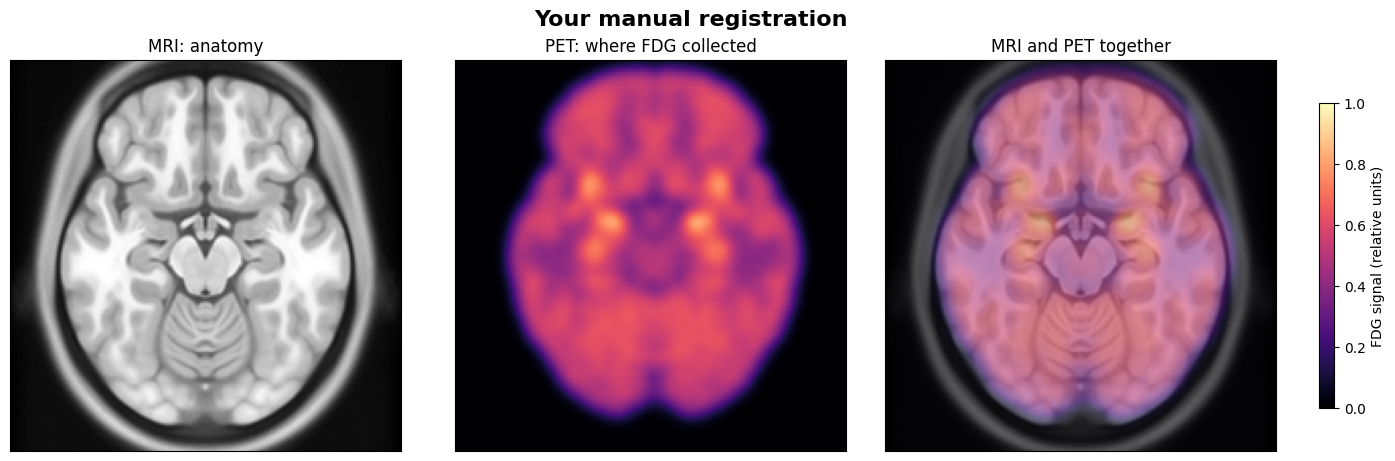

In [25]:
x_correction_mm = -5.0
y_correction_mm = 0.0
outline_to_show = brain_outline  # Hard mode: change brain_outline to None
outline_to_show = None

student_pet = shift_image(challenge_pet, x_correction_mm, y_correction_mm)
show_alignment(mri, student_pet, outline_to_show, title="Your manual registration");

## 4. How will we know the match is better?

Your eyes can judge whether the scans line up. A computer needs a number. We use **correlation**: a way to score how closely two patterns change together. Here, it compares the light and dark patterns across the MRI and PET images. When the images line up better, the correlation usually rises.

The graph below turns that number into a **match score** from 0 to 1, using a range chosen for this exercise. A larger score is better. It is **not** a percentage and does not tell us that the scan is medically correct.

Run the cell, return to the two-number cell, and try to improve the score two or three times.

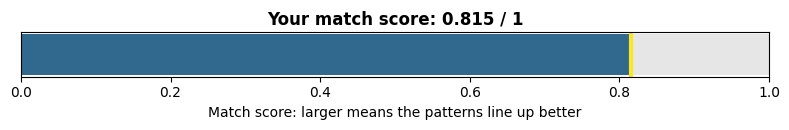

In [26]:
student_score = how_well_matched(mri, student_pet)
show_score(student_score, label="Your match score");

<details><summary><b>NEED A HINT?</b></summary><br>Decide left/right before up/down and change one number at a time. Moving in the wrong direction? Try a negative number. First try whole millimetres, then add one decimal place near your best result.</details>

<details><summary><b>SHOW THE MANUAL SOLUTION</b></summary><br>The best-scoring correction is <code>x_correction_mm = -7.2</code> and <code>y_correction_mm = 5.3</code>.</details>

## 5. Can the computer do our matching job?

The computer can also try many positions for us. This search is called an **optimiser**. Watch it make guesses and gradually focus on the better matches. One graph tracks the left/right and up/down moves; the other tracks the match score.

### PREDICT

Will it beat your current score?

In [27]:
search_animation = animate_optimiser_search(mri, challenge_pet, brain_outline)
display(search_animation)

The animation shows the search exploring possible matches. Once it gets close, it makes smaller moves.

Run the next cell to see the computer's result.
The four pictures show the MRI/PET overlay before the search and after its large, medium, and final moves.
Watch how the PET image shifts closer to the MRI outline.

Computer correction:  x=-7.2 mm, y=+5.3 mm | score 0.993 / 1


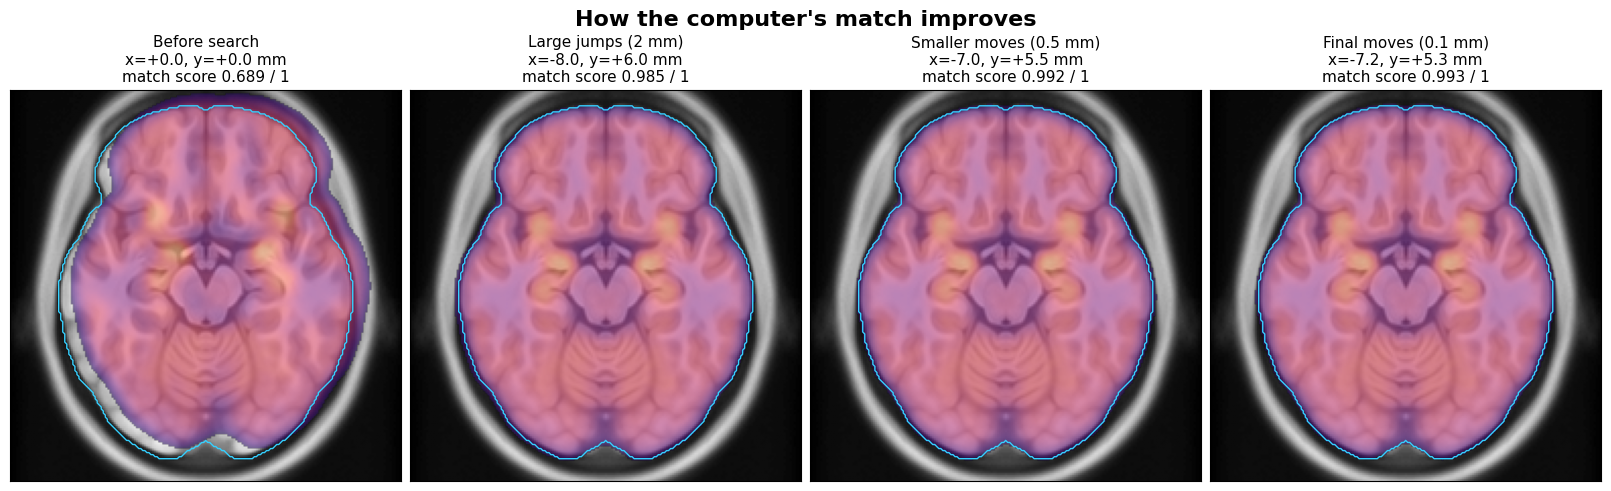

In [28]:
automatic_pet, best_x, best_y, automatic_score, search_steps = optimise(
    mri, challenge_pet, return_steps=True,
)
print(f"Computer correction:  x={best_x:+.1f} mm, y={best_y:+.1f} mm | score {normalise_match_score(automatic_score):.3f} / 1")
show_optimiser_steps(mri, challenge_pet, search_steps, brain_outline);

### Registration is one part of preprocessing

The two scans now line up, so a point in the PET image refers to the same place in the MRI. Getting images ready before measuring them is called **preprocessing**. Registration is one of those preparation steps.

A real study may also check whether each image is usable, correct for movement, and reduce unwanted noise. The exact preparation depends on the scan and the question researchers want to answer.

### WHAT DID YOU NOTICE?

- Did the optimiser beat or equal your result?
- What extra possibilities would it need to test if PET could also rotate or change size?

<details><summary><b>CHECK YOUR ANSWER</b></summary><br>The computer should find x = −7.2 mm and y = +5.3 mm. If PET could also turn or change size, the computer would have many more possible matches to test.</details>

## 6. The scans line up — where should we measure?

We have solved the position problem.
But a bright patch alone does not tell us which brain area it belongs to.
We need a map before we can turn the PET image into measurements from named areas.
An **atlas** is that labelled map of the brain.

Use the atlas explorer below as a reference, then name the areas outlined in pictures **A–D**.
Each picture is a slice through the brain; different areas are easiest to see at different slice levels.

Try these names: **Hippocampus**, **Amygdala**, **Insula**, **Anterior cingulate**, **Thalamus**, **Caudate**, **Putamen**, **Brainstem**, **Cerebellum**, **Lateral occipital**, **Precentral**, **Postcentral**, **Superior temporal**, or **Lateral ventricle**.

In [ ]:
region_to_show = "Hippocampus"  # Change the name to explore the atlas
show_atlas(region_to_show, data);

### Match the pictures to names

Use the atlas explorer to identify each region outlined in pictures **A–D**.
Record the atlas name beside each letter, using the slice level where the outline appears to help you.
Double-click this text cell to fill in your answers, then press **Shift + Enter**:

- A: ...
- B: ...
- C: ...
- D: ...

In [ ]:
show_atlas_quiz(data);

<details><summary><b>CHECK YOUR ANSWERS</b></summary><br>A: Insula. B: Hippocampus. C: Anterior cingulate. D: Amygdala.</details>

### Why choose these four areas for our study?

Earlier research has implicated these four areas in stress-related processes.
That makes them candidates for our study, rather than a list of results we already know we will find.
Their functions give us reasons to investigate them:

- **Hippocampus:** helps us remember events and their context — *What happened last time?*
- **Amygdala:** helps us notice emotionally important events, including possible danger — *Does this matter to me?*
- **Insula:** helps us notice signals from inside the body — *Why is my heart racing?*
- **Anterior cingulate:** helps direct attention and manage competing responses — *What should I focus on or do next?*

The areas work with many others and have many jobs.
Stress is not controlled by one single "stress centre", and there is no rule that these areas all "light up" whenever someone feels stressed.
Our measurements will help us assess which candidates show evidence of a relationship with stress in our study.

The coloured outlines below will help us connect the map to our measurements.

In [ ]:
show_all_atlas_regions(data);

## 7. Measure named brain areas

Because the PET and MRI now line up, we can use the labelled brain map to select the same area in both. The computer can then calculate the **average PET signal** inside each area.

This PET slice shows the hippocampus, amygdala, and insula, so we will measure those three here.
The anterior cingulate is easier to see at another slice level, as the atlas pictures showed.
A whole-brain study can measure all four.

These are **relative FDG signal** values: useful for comparing these teaching images, but not clinical measurements.

In [ ]:
measurement_figure, registered_values = show_region_measurements(
    optimise(mri, challenge_pet)[0], region_masks,
    title="Average PET signal after alignment",
)
display(Markdown(
    "| Brain area | Average FDG signal |\n"
    "|---|---:|\n" +
    "\n".join(f"| {name} | {value:.3f} |" for name, value in registered_values.items())
))

## 8. Compare two PET patterns

Now that we can measure named areas, imagine comparing a low-stress visit with a high-stress visit.
Which candidate regions would show different measurements?
The two example pictures below use the same brain shape, blur, and colour scale.
In the second picture we deliberately added extra signal near some labelled regions, so there is a difference to find and measure.

This is a **teaching example**. It does not show what every person's brain does under stress. Real results vary with the experiment and the person.

### PREDICT

Which regions will show the largest differences between the two patterns?

In [ ]:
comparison_figure, baseline_values, stress_values = compare_pet_patterns(
    baseline_pet, stress_pattern_pet, region_masks
)

### INTERPRET CAREFULLY

1. Why did the atlas make this comparison more meaningful than simply choosing the brightest pixel?
2. Does the second image prove that somebody is stressed?
3. Why does FDG-PET give a different kind of information from an MRI?

<details><summary><b>CHECK YOUR ANSWER</b></summary><br><ol><li>The labelled map lets us compare the same named brain areas.</li><li>No. We deliberately added the differences, and one PET pattern cannot diagnose stress.</li><li>MRI shows structure; PET gives clues about where FDG collected over a period of time.</li></ol></details>

## 9. What changes when we study more people?

Two pictures can suggest a question, but we need more people to investigate a pattern.
Imagine our study has now finished collecting scans.
We repeated the preparation and measurement steps for every volunteer.
Each volunteer rated how stressed they felt from **0 to 10**, and we measured a PET signal in each brain area.
The dots below are simulated data, not real people or a realistic PET test for stress.
Each dot is one volunteer.

Change `number_of_study_participants` below to **5, 10, 50, or 500**, then run the cell again. Each run draws a new group of that size. Which areas seem to have a clearer upward trend? Which look uncertain when you see only a few dots? How many participants in your study do you think you need?

Earlier, correlation helped us compare patterns across two images.
Here we use the same idea to compare two measurements across people: stress rating and PET signal.
The number **r** describes the strength and direction of their straight-line relationship.
That strength is one kind of **effect size**.
Here, **+1** means a very strong upward pattern, **0** means little straight-line pattern, and **−1** means a downward pattern.
A larger group does not make the underlying link stronger; it makes our estimate less easily swayed by chance.

In [ ]:
from workshop_helpers import show_stress_associations

number_of_study_participants = 10  # Try 5, 10, 50, or 500

show_stress_associations(number_of_study_participants);

<details><summary><b>WHAT DO THE DOTS SUGGEST?</b></summary><br>In this teaching example, the amygdala has the strongest built-in link, the insula has a smaller one, the hippocampus has a weak one, and the anterior cingulate has none. With only 5 or 10 people, random variation can make even an area with no built-in link look convincing. At 500, the stronger patterns are clearer, but the weak one may still be hard to judge. Correlation alone cannot show that stress <i>caused</i> a PET change.</details>

## 10. What can our research team conclude?

Return to our question: **what happens in the brain when people are stressed, and which regions are implicated?**
Which candidate regions have the clearest evidence of a relationship with stress in the example study?
Which would need more evidence before you were confident?
Finding support for a candidate strengthens the case for investigating it; a weak or absent pattern means our study has not clearly supported that candidate.

<div style="text-align:center;font-size:1.18em;padding:16px;background:#f3f1fa;border-radius:8px"><b>Collect two views → line them up → use a map → measure → compare across people</b></div>

Try telling the story in one sentence.
Why would one bright patch, or one volunteer, be too little evidence for a conclusion?

<details><summary><b>ONE POSSIBLE SUMMARY</b></summary><br>Our team collects MRI and PET, aligns the scans, measures PET signal in mapped brain areas, and compares those measurements with stress ratings across people. Better preparation and more participants help us judge a pattern; they do not turn it into proof of cause and effect.</details>

**This completes the main workshop.**
The bonus below asks a new question: could we follow changes during a task, rather than compare PET measurements between visits?

# ⭐ BONUS CONTENT — find task-related changes with fMRI

You have reached the optional bonus. We have used PET to follow an injected substance and compare brain areas. Another type of scan, **functional MRI (fMRI)**, can look for changes while a person does a task. It uses the MRI scanner rather than a PET tracer.

The scanner takes many images in a row. Small changes in blood flow and oxygen can affect the signal. This is called the **BOLD signal**; it is an indirect clue about brain activity, not a photograph of neurons firing. Researchers can compare times when someone is resting with times when they are doing a task.

Our made-for-class experiment has 64 images. It alternates between rest and a pretend stress task. Individual images contain plenty of random variation, or **noise**. Can you tell the rest images from the task images just by looking?

In [ ]:
from workshop_helpers import calculate_correlation_map, show_fmri_inputs, show_fmri_result

show_fmri_inputs(data["fmri_timeseries"], data["fmri_task_blocks"]);

## Bonus exercise: let repetition reveal the pattern

The computer follows each small image square, called a **pixel**, across all 64 images. It then uses correlation to ask whether that pixel's signal follows the rest/task pattern:

- correlation near **+1**: the pixel tends to rise and fall with the task;
- correlation near **0**: no consistent relationship;
- correlation near **−1**: the pixel tends to change in the opposite direction.

Try changing the **threshold**, the cut-off for which pixels to show. A lower threshold shows more pixels, including more random noise.

In [ ]:
correlation_threshold = 0.35

calculated_activation = calculate_correlation_map(
    data["fmri_timeseries"], data["fmri_task_design"]
)
show_fmri_result(
    data["fmri_mean"], data["fmri_task_blocks"], data["fmri_task_design"],
    data["fmri_roi_signal"], calculated_activation,
    threshold=correlation_threshold,
);

<details><summary><b>WHAT JUST HAPPENED?</b></summary><br>We added a small task-related signal to two regions in these teaching images. It was hard to spot in one picture. Comparing the repeated images with the task timing made the pattern visible. Real fMRI studies need more steps to check movement, noise, and whether a finding is reliable.</details>

| FDG-PET | Task fMRI |
|---|---|
| One image showing where FDG collected | Many images taken one after another |
| Gives clues about glucose use over a period of time | Looks for signal changes that follow a task |
| Brighter PET colour means more measured FDG signal | A result map shows which pixels followed the task pattern |

### Sources and further reading

- [TemplateFlow: reusable imaging templates and atlases](https://www.templateflow.org/)
- [CerebrA atlas description](https://pmc.ncbi.nlm.nih.gov/articles/PMC7363886/)
- [Review of stress-induction methods in the MRI scanner](https://pubmed.ncbi.nlm.nih.gov/30631946/)
- [Meta-analysis of BOLD changes during acute stress](https://pubmed.ncbi.nlm.nih.gov/33497786/)

**About these images:** The MRI anatomy and region labels come from shared research resources. PET and bonus fMRI signals were made for this lesson. None are patient scans. See `DATA_SOURCES.md` for the exact data sources, licences, and limits of these examples.